# Prerequisites

In [1]:
# Importing Tools for Analysing DNA Sequencing
import scanpy as sp
import numpy as np

In [2]:
# Importing PBMC 3K Dataset
df = sp.datasets.pbmc3k()

In [3]:
# Gene Expression matrix X's shape
print(df.X.shape)
# => 2700 Cells with 32738 Gene Data

(2700, 32738)


In [4]:
print(df.obs)
# No.of Cells
# The Indexes are actually the Cell barcodes which are totally random for each cell - ``cell id``

Empty DataFrame
Columns: []
Index: [AAACATACAACCAC-1, AAACATTGAGCTAC-1, AAACATTGATCAGC-1, AAACCGTGCTTCCG-1, AAACCGTGTATGCG-1, AAACGCACTGGTAC-1, AAACGCTGACCAGT-1, AAACGCTGGTTCTT-1, AAACGCTGTAGCCA-1, AAACGCTGTTTCTG-1, AAACTTGAAAAACG-1, AAACTTGATCCAGA-1, AAAGAGACGAGATA-1, AAAGAGACGCGAGA-1, AAAGAGACGGACTT-1, AAAGAGACGGCATT-1, AAAGATCTGGGCAA-1, AAAGCAGAAGCCAT-1, AAAGCAGATATCGG-1, AAAGCCTGTATGCG-1, AAAGGCCTGTCTAG-1, AAAGTTTGATCACG-1, AAAGTTTGGGGTGA-1, AAAGTTTGTAGAGA-1, AAAGTTTGTAGCGT-1, AAATCAACAATGCC-1, AAATCAACACCAGT-1, AAATCAACCAGGAG-1, AAATCAACCCTATT-1, AAATCAACGGAAGC-1, AAATCAACTCGCAA-1, AAATCATGACCACA-1, AAATCCCTCCACAA-1, AAATCCCTGCTATG-1, AAATGTTGAACGAA-1, AAATGTTGCCACAA-1, AAATGTTGTGGCAT-1, AAATTCGAAGGTTC-1, AAATTCGAATCACG-1, AAATTCGAGCTGAT-1, AAATTCGAGGAGTG-1, AAATTCGATTCTCA-1, AAATTGACACGACT-1, AAATTGACTCGCTC-1, AACAAACTCATTTC-1, AACAAACTTTCGTT-1, AACAATACGACGAG-1, AACACGTGCAGAGG-1, AACACGTGGAAAGT-1, AACACGTGGAACCT-1, AACACGTGGCTACA-1, AACACGTGTACGAC-1, AACAGCACAAGAGT-1, AACATTGATG

In [5]:
print(df.var)
# No.of Genes per cell
# The index is the name of the gene - gene-ids is the genetic identity (both are same)

                     gene_ids
index                        
MIR1302-10    ENSG00000243485
FAM138A       ENSG00000237613
OR4F5         ENSG00000186092
RP11-34P13.7  ENSG00000238009
RP11-34P13.8  ENSG00000239945
...                       ...
AC145205.1    ENSG00000215635
BAGE5         ENSG00000268590
CU459201.1    ENSG00000251180
AC002321.2    ENSG00000215616
AC002321.1    ENSG00000215611

[32738 rows x 1 columns]


In [6]:
print(df.uns) # Unspecified Annotation
print(df.obsm)
print(df.varm)
print(df.layers)
print(df.shape)
print(df.filename)

OrderedDict()
AxisArrays with keys: 
AxisArrays with keys: 
Layers with keys: 
(2700, 32738)
None


# Quality Control

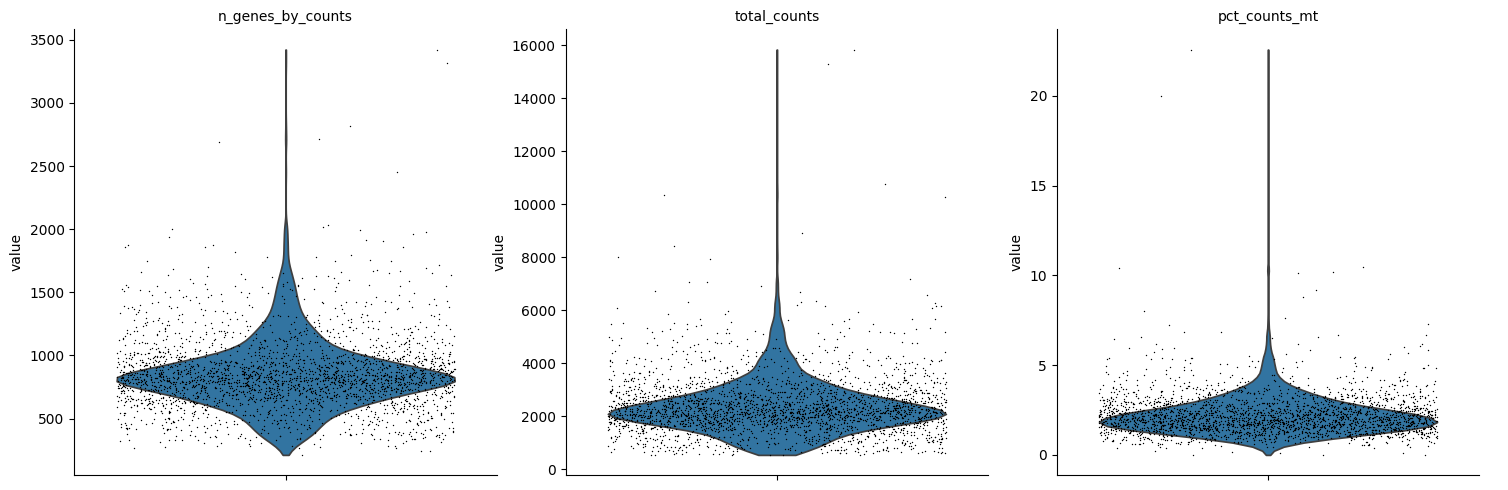

In [7]:
import matplotlib.pyplot as plt

# 1. Add QC metrics
df.var['mt'] = df.var_names.str.startswith('MT-')  # Mitochondrial genes
sp.pp.calculate_qc_metrics(df, qc_vars=['mt'], inplace=True)

# 2. Visualize QC
sp.pl.violin(df, ['n_genes_by_counts', 'total_counts', 'pct_counts_mt'],
             jitter=0.4, multi_panel=True)

# 3. Filter cells and genes
df = df[df.obs.n_genes_by_counts < 2500, :]  # Remove cells with too many genes
df = df[df.obs.pct_counts_mt < 5, :]        # Remove cells with high MT% 
df = df[:, df.var.n_cells_by_counts > 3]    # Keep genes expressed in at least 3 cells

# Normalization

In [8]:
# Normalize total counts per cell to 10,000
sp.pp.normalize_total(df, target_sum=1e4)
# Logarithmic transform
sp.pp.log1p(df)

/home/bhuvan1707/Desktop/IBS Project/ibs-venv/lib/python3.10/site-packages/scanpy/preprocessing/_normalization.py:269: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


# Identifying Highly Variable Genes

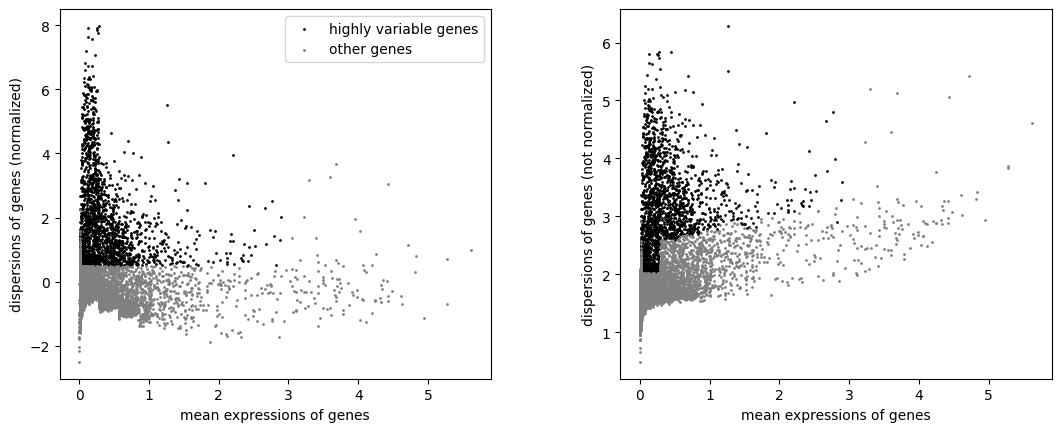

In [9]:
sp.pp.highly_variable_genes(df, min_mean=0.0125, max_mean=3, min_disp=0.5)
sp.pl.highly_variable_genes(df)  # visualize

# Keep only highly variable genes
df = df[:, df.var.highly_variable]

# Scaling of the data

In [10]:
sp.pp.scale(df, max_value=10)


/home/bhuvan1707/Desktop/IBS Project/ibs-venv/lib/python3.10/site-packages/scanpy/preprocessing/_scale.py:309: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)
/home/bhuvan1707/.pyenv/versions/3.10.13/lib/python3.10/functools.py:889: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


# Dimensionality Reduction

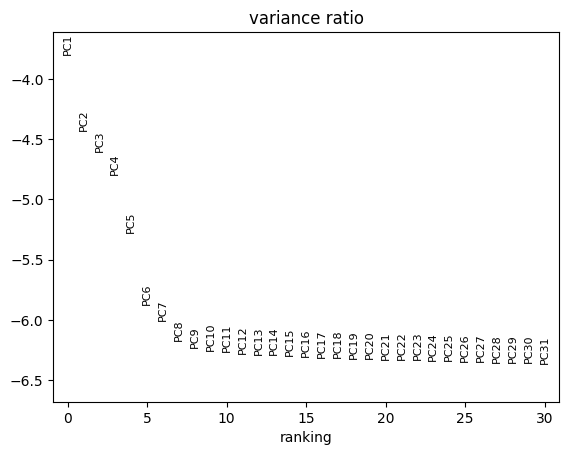

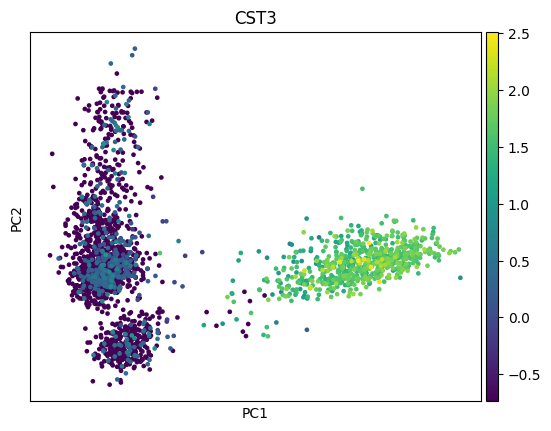

In [11]:
sp.tl.pca(df, svd_solver='arpack')
sp.pl.pca_variance_ratio(df, log=True)  # Scree plot
sp.pl.pca(df, color='CST3')  # Visualize PCA with a known marker gene

# Nearest Neighbor graph - Preparing for t-SNE and UMAP

In [12]:
sp.pp.neighbors(df, n_neighbors=10, n_pcs=30)


/home/bhuvan1707/Desktop/IBS Project/ibs-venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# t-SNE Dimension reduction

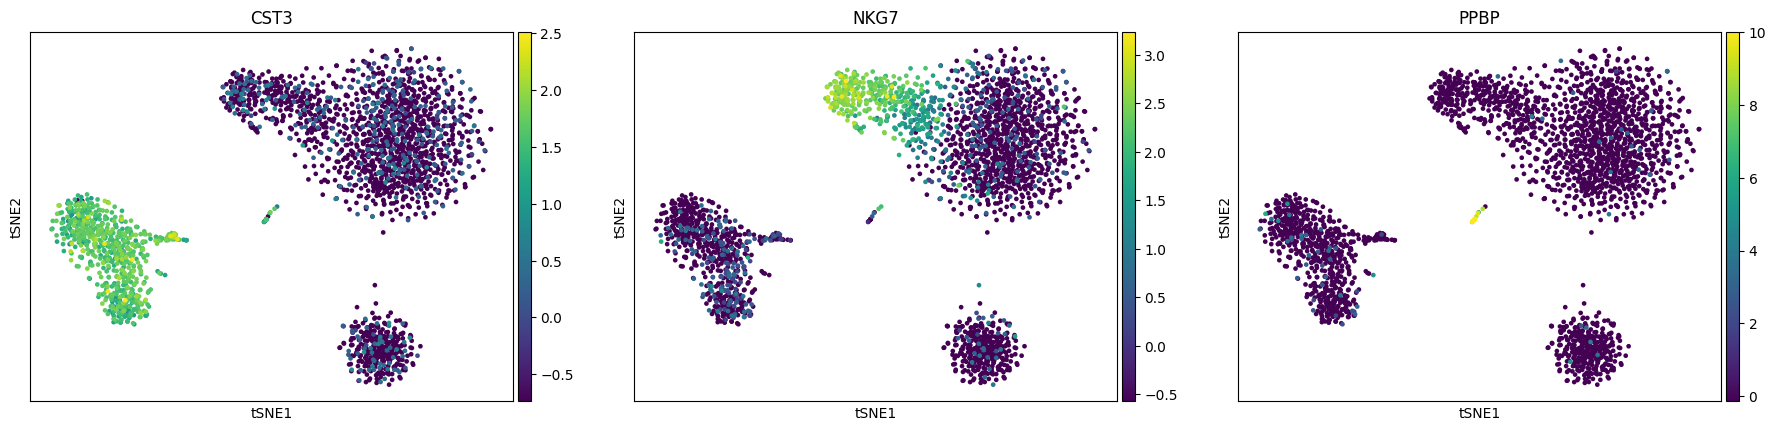

In [13]:
# t-SNE
sp.tl.tsne(df)
sp.pl.tsne(df, color=['CST3', 'NKG7', 'PPBP'])


# UMAP Dimension reduction

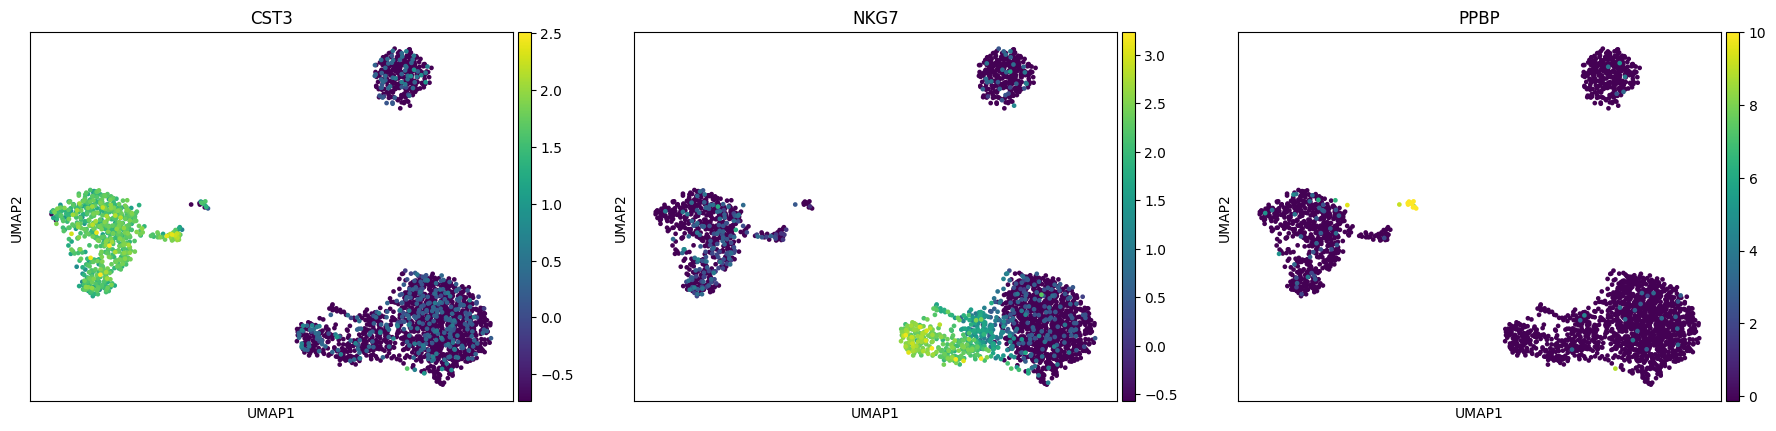

In [14]:
# UMAP
sp.tl.umap(df)
sp.pl.umap(df, color=['CST3', 'NKG7', 'PPBP'])  # Known immune cell markers

# Leiden Clustering

/tmp/ipykernel_509594/810561526.py:1: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sp.tl.leiden(df, resolution=0.5)


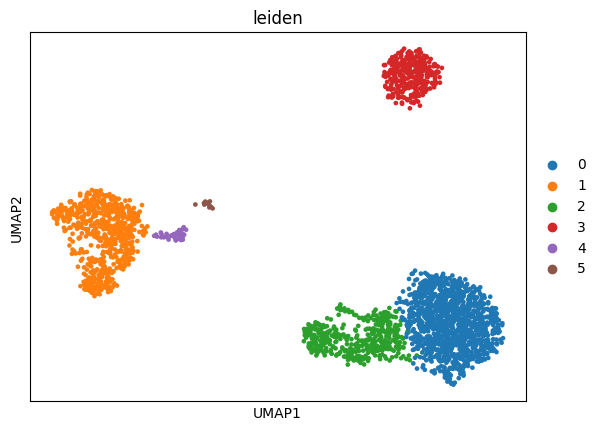

In [18]:
sp.tl.leiden(df, resolution=0.5)
sp.pl.umap(df, color=['leiden'])  # visualize clusters


# Cluster Validation

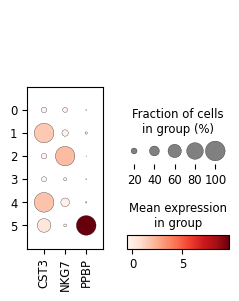

In [19]:
marker_genes = ['CST3', 'NKG7', 'PPBP']
sp.pl.dotplot(df, marker_genes, groupby='leiden')

# UMAP for KMeans Clustering

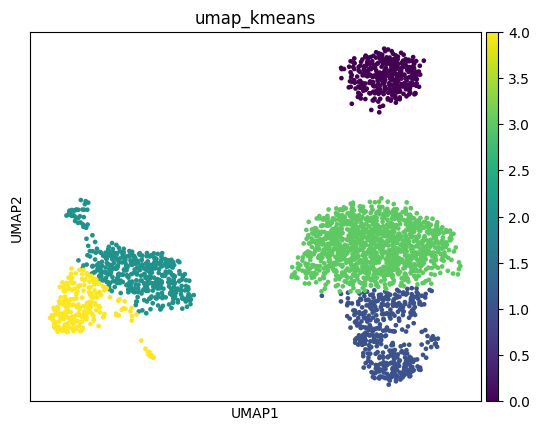

In [20]:
import scanpy as sp
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# --- Step 1: Run PCA first (UMAP depends on it) ---
sp.tl.pca(df, svd_solver='arpack')
sp.pp.neighbors(df, n_neighbors=10, n_pcs=40)

# --- Step 2: Run UMAP ---
sp.tl.umap(df)

# UMAP results are stored in df.obsm['X_umap']
umap_data = df.obsm['X_umap']

# --- Step 3: Run clustering (K-Means) on UMAP data ---
kmeans = KMeans(n_clusters=5, random_state=42)
df.obs['umap_kmeans'] = kmeans.fit_predict(umap_data)

# --- Step 4: Visualize clusters on UMAP plot ---
sp.pl.umap(df, color=['umap_kmeans'])

In [26]:
# ===========================
# --- Step 5: Evaluate Clustering ---
# ===========================

from sklearn.metrics import (
    silhouette_score, calinski_harabasz_score, davies_bouldin_score,
    adjusted_rand_score, normalized_mutual_info_score, f1_score, accuracy_score
)

# UMAP embeddings used for clustering
umap_data = df.obsm['X_umap']
predicted_labels = df.obs['umap_kmeans']

# ===========================
# --- A. Unsupervised Metrics (No Ground Truth) ---
# ===========================
silhouette = silhouette_score(umap_data, predicted_labels)
calinski = calinski_harabasz_score(umap_data, predicted_labels)
davies = davies_bouldin_score(umap_data, predicted_labels)

print("\n--- Unsupervised Metrics ---")
print(f"Silhouette Score: {silhouette:.4f} (Higher is better, range: -1 to 1)")
print(f"Calinski-Harabasz Index: {calinski:.4f} (Higher is better)")
print(f"Davies-Bouldin Index: {davies:.4f} (Lower is better)")

# ===========================
# --- B. Supervised Metrics (If True Labels Available) ---
# ===========================
# Check if true labels exist in df.obs (e.g., known cell types)
if 'true_cell_type' in df.obs.columns:
    true_labels = df.obs['true_cell_type']
    
    ari = adjusted_rand_score(true_labels, predicted_labels)
    nmi = normalized_mutual_info_score(true_labels, predicted_labels)
    f1 = f1_score(true_labels, predicted_labels, average='weighted')
    acc = accuracy_score(true_labels, predicted_labels)

    print("\n--- Supervised Metrics (With Ground Truth) ---")
    print(f"Adjusted Rand Index (ARI): {ari:.4f} (Higher is better, max=1)")
    print(f"Normalized Mutual Information (NMI): {nmi:.4f} (Higher is better, max=1)")
    print(f"F1 Score (Weighted): {f1:.4f}")
    print(f"Accuracy: {acc:.4f}")
else:
    print("\nNo ground truth labels found in df.obs['true_cell_type']. "
          "Skipping supervised evaluation.")



--- Unsupervised Metrics ---
Silhouette Score: 0.5364 (Higher is better, range: -1 to 1)
Calinski-Harabasz Index: 8520.6602 (Higher is better)
Davies-Bouldin Index: 0.7040 (Lower is better)

No ground truth labels found in df.obs['true_cell_type']. Skipping supervised evaluation.


# t-SNE and KMeans

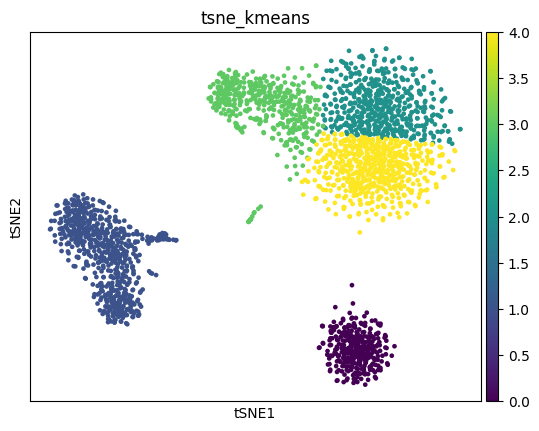

In [27]:
# Run t-SNE
sp.tl.tsne(df)

# Extract t-SNE coordinates
tsne_data = df.obsm['X_tsne']

# Cluster using K-Means
kmeans = KMeans(n_clusters=5, random_state=42)
df.obs['tsne_kmeans'] = kmeans.fit_predict(tsne_data)

# Visualize
sp.pl.tsne(df, color=['tsne_kmeans'])

In [33]:
# ===========================
# --- Step 5: Evaluate Clustering ---
# ===========================

predicted_labels = df.obs['tsne_kmeans']

# --- A. Unsupervised Metrics ---
silhouette = silhouette_score(tsne_data, predicted_labels)
calinski = calinski_harabasz_score(tsne_data, predicted_labels)
davies = davies_bouldin_score(tsne_data, predicted_labels)

print("\n--- Unsupervised Metrics ---")
print(f"Silhouette Score: {silhouette:.4f} (Higher is better, range: -1 to 1)")
print(f"Calinski-Harabasz Index: {calinski:.4f} (Higher is better)")
print(f"Davies-Bouldin Index: {davies:.4f} (Lower is better)")

# --- B. Supervised Metrics (Optional, only if true labels exist) ---
if 'true_cell_type' in df.obs.columns:
    true_labels = df.obs['true_cell_type']
    
    ari = adjusted_rand_score(true_labels, predicted_labels)
    nmi = normalized_mutual_info_score(true_labels, predicted_labels)
    f1 = f1_score(true_labels, predicted_labels, average='weighted')
    acc = accuracy_score(true_labels, predicted_labels)

    print("\n--- Supervised Metrics (With Ground Truth) ---")
    print(f"Adjusted Rand Index (ARI): {ari:.4f}")
    print(f"Normalized Mutual Information (NMI): {nmi:.4f}")
    print(f"F1 Score (Weighted): {f1:.4f}")
    print(f"Accuracy: {acc:.4f}")
else:
    print("\nNo ground truth labels found in df.obs['true_cell_type']. "
          "Skipping supervised evaluation.")


--- Unsupervised Metrics ---
Silhouette Score: 0.5597 (Higher is better, range: -1 to 1)
Calinski-Harabasz Index: 9009.5059 (Higher is better)
Davies-Bouldin Index: 0.6647 (Lower is better)

No ground truth labels found in df.obs['true_cell_type']. Skipping supervised evaluation.


# PCA and KMeans

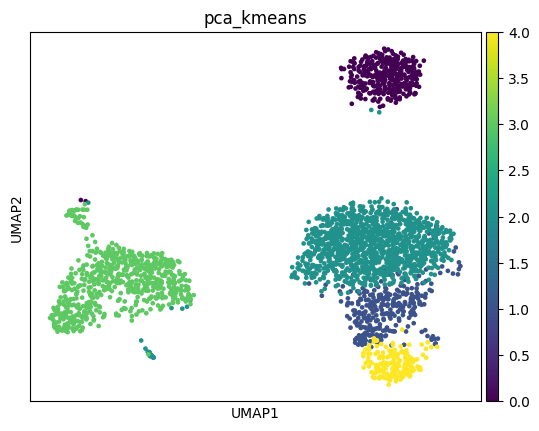

In [29]:
import scanpy as sp
from sklearn.cluster import KMeans

# --- Step 1: Run PCA ---
sp.tl.pca(df, svd_solver='arpack')

# Extract PCA results (first 50 PCs recommended)
pca_data = df.obsm['X_pca'][:, :50]  # Top 50 PCs

# --- Step 2: Cluster using K-Means ---
kmeans = KMeans(n_clusters=5, random_state=42)
df.obs['pca_kmeans'] = kmeans.fit_predict(pca_data)

# --- Step 3: Visualize using UMAP for clarity ---
sp.pp.neighbors(df, n_neighbors=10, n_pcs=40)
sp.tl.umap(df)

sp.pl.umap(df, color=['pca_kmeans'])


In [32]:
# ===========================
# --- Step 4: Evaluate Clustering ---
# ===========================

predicted_labels = df.obs['pca_kmeans']

# --- A. Unsupervised Metrics ---
silhouette = silhouette_score(pca_data, predicted_labels)
calinski = calinski_harabasz_score(pca_data, predicted_labels)
davies = davies_bouldin_score(pca_data, predicted_labels)

print("\n--- Unsupervised Metrics ---")
print(f"Silhouette Score: {silhouette:.4f} (Higher is better, range: -1 to 1)")
print(f"Calinski-Harabasz Index: {calinski:.4f} (Higher is better)")
print(f"Davies-Bouldin Index: {davies:.4f} (Lower is better)")

# --- B. Supervised Metrics (Optional) ---
# Run this ONLY if ground truth labels are available in the dataset
if 'true_cell_type' in df.obs.columns:
    true_labels = df.obs['true_cell_type']
    
    ari = adjusted_rand_score(true_labels, predicted_labels)
    nmi = normalized_mutual_info_score(true_labels, predicted_labels)
    f1 = f1_score(true_labels, predicted_labels, average='weighted')
    acc = accuracy_score(true_labels, predicted_labels)

    print("\n--- Supervised Metrics (With Ground Truth) ---")
    print(f"Adjusted Rand Index (ARI): {ari:.4f}")
    print(f"Normalized Mutual Information (NMI): {nmi:.4f}")
    print(f"F1 Score (Weighted): {f1:.4f}")
    print(f"Accuracy: {acc:.4f}")
else:
    print("\nNo ground truth labels found in df.obs['true_cell_type']. "
          "Skipping supervised evaluation.")


--- Unsupervised Metrics ---
Silhouette Score: 0.1434 (Higher is better, range: -1 to 1)
Calinski-Harabasz Index: 269.2698 (Higher is better)
Davies-Bouldin Index: 2.5141 (Lower is better)

No ground truth labels found in df.obs['true_cell_type']. Skipping supervised evaluation.
